# H12. FS1 포화 횟수가 부품 상태와 관련 있는가

| 항목 | 내용 |
|---|---|
| 질문 | 유량 센서 FS1이 측정 한계에 걸린 횟수에도 부품 정보가 있을까? |
| 귀무가설 H0 | FS1 포화 횟수 분포는 펌프·밸브 상태와 관계없이 같다 |
| 대립가설 H1 | 상태에 따라 다르다 |
| 검정 | Kruskal-Wallis (펌프, 밸브 → Holm) → Dunn, 효과 크기 ε² |
| 출처 (EDA) | F05 FS1 포화 히스토그램 |
| 데이터 | 원본 FS1.txt → 사이클별 최댓값 도달 횟수 |
| 왜 중요한가 | 포화 값을 지우지 않고 '포화 횟수' 특징으로 남긴 처리가 맞는지 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

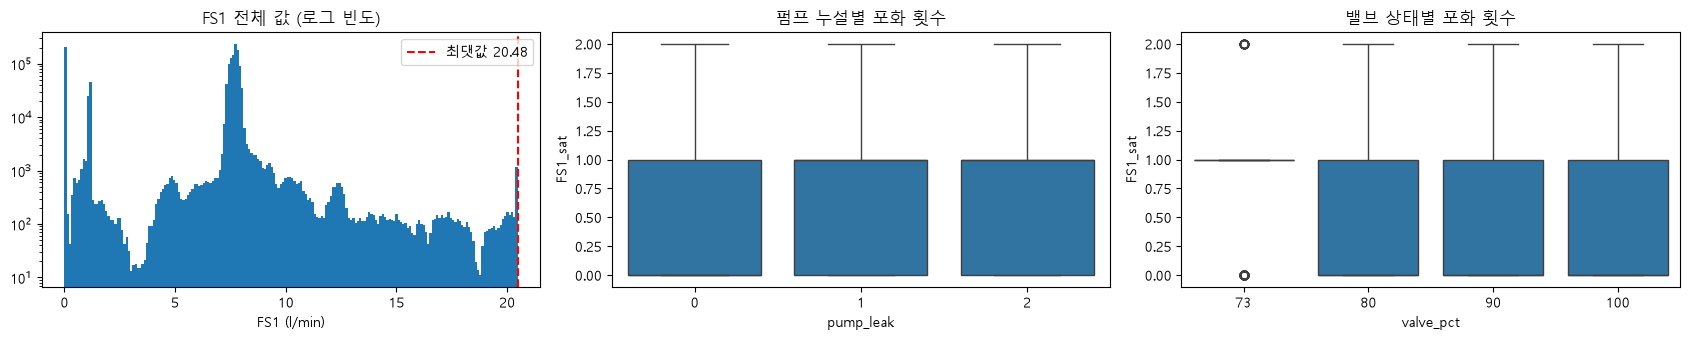

In [2]:
fs1 = raw("FS1"); SAT = fs1.max(); cyc["FS1_sat"] = np.isclose(fs1, SAT).sum(axis=1)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.5))
axes[0].hist(fs1.ravel(), bins=200, log=True); axes[0].axvline(SAT, color="r", ls="--", label=f"최댓값 {SAT:.2f}"); axes[0].legend(); axes[0].set_xlabel("FS1 (l/min)"); axes[0].set_title("FS1 전체 값 (로그 빈도)")
sns.boxplot(data=cyc, x="pump_leak", y="FS1_sat", ax=axes[1]); axes[1].set_title("펌프 누설별 포화 횟수")
sns.boxplot(data=cyc, x="valve_pct", y="FS1_sat", ax=axes[2]); axes[2].set_title("밸브 상태별 포화 횟수")
plt.tight_layout(); plt.show()

## 2. 기술통계

In [3]:
print("포화가 1번 이상 있는 사이클:", (cyc.FS1_sat > 0).sum(), "/", len(cyc))
for c in ["pump_leak", "valve_pct"]: display(cyc.groupby(c)["FS1_sat"].describe().round(2))

포화가 1번 이상 있는 사이클: 1002 / 2205


,count,mean,std,min,25%,50%,75%,max
pump_leak,,,,,,,,
0,1221.0,0.39,0.49,0.0,0.0,0.0,1.0,2.0
1,492.0,0.62,0.57,0.0,0.0,1.0,1.0,2.0
2,492.0,0.55,0.57,0.0,0.0,1.0,1.0,2.0


,count,mean,std,min,25%,50%,75%,max
valve_pct,,,,,,,,
73,360.0,0.85,0.50,0.0,1.0,1.0,1.0,2.0
80,360.0,0.27,0.46,0.0,0.0,0.0,1.0,2.0
90,360.0,0.35,0.51,0.0,0.0,0.0,1.0,2.0
100,1125.0,0.46,0.53,0.0,0.0,0.0,1.0,2.0


## 3. 가정 확인 → 검정 방법 고르기

- **정규성:** 그룹마다 D'Agostino K² 검정과 Q-Q 플롯으로 봅니다. 표본이 크면 검정은 작은 벗어남에도 기각하므로 **Q-Q 플롯을 함께** 봅니다.
- **등분산:** Levene 검정(중앙값 기준)으로 봅니다.
- 정규성과 등분산이 성립하면 일원 ANOVA를 쓰고, 성립하지 않으면 **Kruskal-Wallis(비모수)**를 씁니다.

,그룹,n,왜도,K2,정규성_p,정규분포
0,0,1221,0.54,8632.0,0.00e+00,아니오
1,1,492,0.26,35.7,1.74e-08,아니오
2,2,492,0.46,44.9,1.74e-10,아니오


Levene W = 16.55, p = 7.33e-08 → 등분산: 아니오


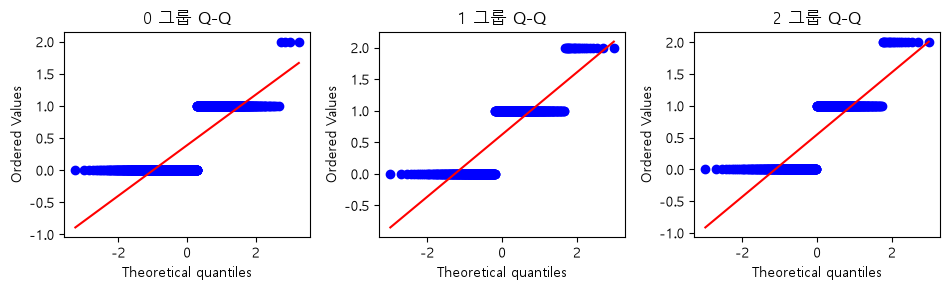

선택한 검정: Kruskal-Wallis (비모수)


In [4]:
tab, lev = assumption_table(cyc['FS1_sat'], cyc['pump_leak'])
display(tab.style.format({"왜도": "{:.2f}", "K2": "{:.1f}", "정규성_p": "{:.2e}"}))
print(f"Levene W = {lev['W']:.2f}, p = {lev['p']:.2e} → 등분산: {lev['등분산']}")
groups = sorted(cyc['pump_leak'].unique())
fig, axes = plt.subplots(1, len(groups), figsize=(3.2 * len(groups), 3))
for ax, gv in zip(axes, groups):
    stats.probplot(cyc.loc[cyc['pump_leak'] == gv, 'FS1_sat'].dropna(), dist="norm", plot=ax); ax.set_title(f"{gv} 그룹 Q-Q")
plt.tight_layout(); plt.show()
use_nonparam = (tab["정규분포"] == "아니오").any() or lev["등분산"] == "아니오"
print("선택한 검정:", "Kruskal-Wallis (비모수)" if use_nonparam else "일원 ANOVA")

## 4. 정상성 확인

사이클 순서대로 본 이 특징이 **정상(평균·분산이 시간에 따라 일정)**인지 확인합니다. ADF(H0: 비정상)와 KPSS(H0: 정상)는 질문이 반대라서 함께 봅니다.

- 비정상이거나 자기상관이 크면 "관측값이 서로 독립"이라는 검정의 가정이 약해집니다. 그래서 7단계에서 **50사이클 블록 평균으로 다시 검정**합니다.
- KPSS p가 0.01이나 0.10으로 나오면 경계값입니다. 각각 "0.01 이하", "0.10 이상"으로 읽습니다.


,특징,계열,ADF_p,KPSS_p,판정
0,FS1_sat,원값,0.0025,0.010,추세·구조변화(둘 다 기각)
1,FS1_sat,1차 차분,0.0000,0.100,정상


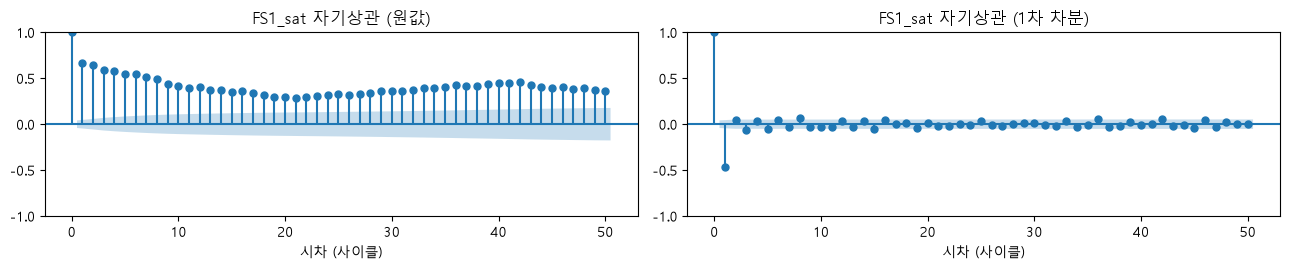

In [5]:
st = stationarity(cyc, ['FS1_sat'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['FS1_sat'], "FS1_sat 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['FS1_sat'].diff(), "FS1_sat 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

## 5. 가설검정 (p-값)

In [6]:
res = pd.DataFrame([dict(부품=COMP[c], **kruskal_test(cyc["FS1_sat"], cyc[c])) for c in ["pump_leak", "valve_pct"]])
res["p_holm"] = holm(res["p"]); res["효과"] = res["eps2"].map(size_label)
display(res.style.format({"H": "{:.1f}", "p": "{:.2e}", "p_holm": "{:.2e}", "eps2": "{:.3f}"}))

,부품,H,df,p,eps2,n,p_holm,효과
0,펌프 누설,67.8,2,1.86e-15,0.031,2205,1.86e-15,작음
1,밸브(%),245.2,3,7.04e-53,0.111,2205,1.41e-52,중간


## 6. 사후검정·효과 크기

In [7]:
for c in ["pump_leak", "valve_pct"]:
    print(f"[{COMP[c]}]"); display(dunn_test(cyc["FS1_sat"], cyc[c]).style.format({"z": "{:.2f}", "p": "{:.2e}", "p_holm": "{:.2e}"}))

[펌프 누설]


,쌍,z,p,p_holm,유의
0,0 vs 1,-7.68,1.59e-14,4.77e-14,예
1,0 vs 2,-5.05,4.30e-07,8.61e-07,예
2,1 vs 2,2.20,2.79e-02,2.79e-02,예


[밸브(%)]


,쌍,z,p,p_holm,유의
0,73 vs 80,14.37,8.40e-47,5.04e-46,예
1,73 vs 90,12.52,5.63e-36,2.82e-35,예
2,73 vs 100,11.67,1.79e-31,7.17e-31,예
3,80 vs 90,-1.84,6.52e-02,6.52e-02,아니오
4,80 vs 100,-6.01,1.82e-09,5.46e-09,예
5,90 vs 100,-3.74,1.82e-04,3.64e-04,예


## 7. 블록 평균으로 재확인

In [8]:
blk = {}
for c in ["pump_leak", "valve_pct"]:
    b = block_means(cyc, "FS1_sat", c); blk[c] = kruskal_test(b["FS1_sat"], b[c]); print(f"{COMP[c]}: 블록 {len(b)}개, p = {blk[c]['p']:.2e}, ε² = {blk[c]['eps2']:.3f}")

펌프 누설: 블록 80개, p = 2.76e-02, ε² = 0.091
밸브(%): 블록 143개, p = 7.57e-08, ε² = 0.253


## 8. 최종 판정

In [9]:
final = pd.DataFrame([dict(가설="H12", 부품=res.부품[i], 통계량=f"H({res.df[i]}) = {res.H[i]:.1f}", p_holm=res.p_holm[i],
    효과크기=f"ε² = {res.eps2[i]:.3f} ({res.효과[i]})", 블록_p=blk[c]["p"], 판정="H0 기각" if res.p_holm[i] < ALPHA and blk[c]["p"] < ALPHA else "H0 유지")
    for i, c in enumerate(["pump_leak", "valve_pct"])])
display(final)
save_result("H12", title="FS1 포화 횟수 × 펌프·밸브", test="Kruskal-Wallis (Holm)", stat=" / ".join(final.통계량), p=float(final.p_holm.max()),
            effect=" / ".join(final.부품 + " " + final.효과크기), verdict="H0 기각" if (final.판정 == "H0 기각").all() else "일부 H0 유지")

,가설,부품,통계량,p_holm,효과크기,블록_p,판정
0,H12,펌프 누설,H(2) = 67.8,1.864170e-15,ε² = 0.031 (작음),2.763670e-02,H0 기각
1,H12,밸브(%),H(3) = 245.2,1.408996e-52,ε² = 0.111 (중간),7.573765e-08,H0 기각


저장: results/H12.json


## 9. 해석과 결정

- 포화 횟수는 펌프(효과 작음)와 밸브(효과 중간)에 따라 다릅니다. 포화 자체에도 부품 정보가 들어 있다는 뜻입니다.
- **결정:** 포화 값을 잘라 내거나 지우지 않고, **포화 횟수를 특징(FS1_sat_n)으로 남긴 전처리가 맞습니다.** 블록 평균 재확인에서 유의성이 약해지면, 효과가 시간 배치에 일부 기대고 있다는 뜻이므로 보고서에 함께 적습니다.